ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Loading fMRI data...


[fetch_development_fmri] Added README.md to /root/nilearn_data

[fetch_development_fmri] Dataset created in /root/nilearn_data/development_fmri

...

[fetch_atlas_schaefer_2018] Dataset created in /root/nilearn_data/schaefer_2018

[fetch_atlas_schaefer_2018] Downloading data from https://raw.githubusercontent.com/ThomasYeoLab/CBIG/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/Schaefer2018_100Parcels_7Networks_order.txt ...

[fetch_atlas_schaefer_2018]  ...done. (0 seconds, 0 min)

[fetch_atlas_schaefer_2018] Downloading data from https://raw.githubusercontent.com/ThomasYeoLab/CBIG/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii.gz ...

[fetch_atlas_schaefer_2018]  ...done. (0 seconds, 0 min)

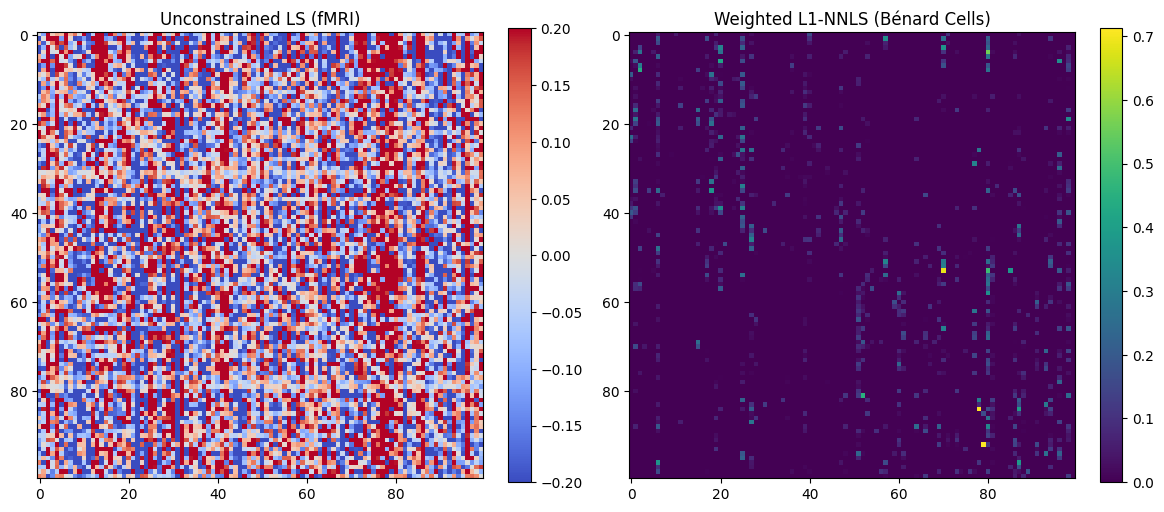


=== fMRI RESULTS ===
LS negative: 48.9%
NNLS negative: 0.0%
Mean length NNLS: 82.11 mm
Mean length Weighted: 58.29 mm


In [1]:
# ==========================================
# Analysis of fMRI BOLD signals
# ==========================================
!pip install nilearn -q

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import nnls, minimize
from scipy.linalg import convolution_matrix
from scipy.stats import gamma
from scipy.spatial.distance import cdist
from scipy.signal import detrend
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker
from nilearn.plotting import find_parcellation_cut_coords

# 1. Load Data
print("Loading fMRI data...")
data = datasets.fetch_development_fmri(n_subjects=1)
bold_path = data.func[0]
atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=7)

masker = NiftiLabelsMasker(labels_img=atlas.maps, standardize=None, detrend=False, t_r=2.0)
ts = masker.fit_transform(bold_path)
n_rois = ts.shape[1]

# 2. Preprocess: Detrend and shift to positive
ts_detr = detrend(ts, axis=0, type='linear')
ts_pos = ts_detr - ts_detr.min(axis=0) + 1e-6

X_lag = ts_pos[:-1, :]
Y_cur = ts_pos[1:, :]

# 3. HRF and NNLS / LS
def hrf_double_gamma(tr=2.0, n_samples=32):
    t = np.arange(n_samples) * tr
    peak = gamma.pdf(t, 6) - gamma.pdf(t, 16) / 6.0
    return peak / peak.sum()

hrf = hrf_double_gamma(tr=2.0)
H = convolution_matrix(hrf, len(ts_pos), mode='full')[:len(ts_pos)]

X_hat = np.zeros_like(ts_pos)
for j in range(n_rois):
    x, _ = nnls(H, ts_pos[:, j])
    X_hat[:, j] = x

X_lag = X_hat[:-1, :]
Y_cur = X_hat[1:, :]

W_nnls = np.zeros((n_rois, n_rois))
W_ls = np.zeros((n_rois, n_rois))

for i in range(n_rois):
    X_pred = X_lag.copy()
    X_pred[:, i] = 0.0
    w_i, _ = nnls(X_pred, Y_cur[:, i])
    W_nnls[i, :] = w_i
    w_ls, *_ = np.linalg.lstsq(X_pred, Y_cur[:, i], rcond=None)
    W_ls[i, :] = w_ls

# 4. Weighted L1-NNLS
coords = find_parcellation_cut_coords(atlas.maps)
dist_matrix = cdist(coords, coords)
dist_norm = dist_matrix / dist_matrix.max()

scale_X, scale_Y = X_lag.max(), Y_cur.max()
X_lag_norm = X_lag / scale_X
Y_cur_norm = Y_cur / scale_Y
lambda_reg = 0.5
W_weighted = np.zeros((n_rois, n_rois))

for i in range(n_rois):
    X_pred = X_lag_norm.copy()
    X_pred[:, i] = 0.0
    y = Y_cur_norm[:, i]
    d = dist_norm[i, :]

    def obj(w): return np.sum((X_pred @ w - y)**2) + lambda_reg * np.sum(d * w)
    def grad(w): return 2 * X_pred.T @ (X_pred @ w - y) + lambda_reg * d

    res = minimize(obj, np.zeros(n_rois), method='L-BFGS-B', jac=grad, bounds=[(0, None)]*n_rois)
    W_weighted[i, :] = res.x
W_weighted = W_weighted * (scale_Y / scale_X)

# 5. Plotting & Metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(W_ls, cmap='coolwarm', vmin=-0.2, vmax=0.2)
axes[0].set_title('Unconstrained LS (fMRI)')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(W_weighted, cmap='viridis')
axes[1].set_title('Weighted L1-NNLS (Bénard Cells)')
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.show()

print("\n=== fMRI RESULTS ===")
print(f"LS negative: {(W_ls < 0).mean() * 100:.1f}%")
print(f"NNLS negative: {(W_nnls < 0).mean() * 100:.1f}%")

thr = 0.05
mask_base = W_nnls > thr
mask_weighted = W_weighted > thr
np.fill_diagonal(mask_base, False)
np.fill_diagonal(mask_weighted, False)

mean_dist_base = dist_matrix[mask_base].mean()
mean_dist_weighted = dist_matrix[mask_weighted].mean()
print(f"Mean length NNLS: {mean_dist_base:.2f} mm")
print(f"Mean length Weighted: {mean_dist_weighted:.2f} mm")